# 공유자전거 대여 수요 예측 — 회귀 미니프로젝트

**모듈 1 · Day 1 · 8교시 / TODO Notebook**

- 데이터: UCI Bike Sharing Dataset의 `hour.csv`
- 예측 대상: 시간당 총 대여량 `cnt`
- 개발 방법: **공통 코드 실행 → TODO 직접 구현 → CP-01~08 결과 확인**
- 이 Notebook은 *미완성 실습 템플릿*입니다. `...` 부분을 완성하기 전에는 일부 셀이 오류를 발생할 수 있습니다.
- 실습 안내 교안과 함께 사용합니다. TODO의 정답이나 모델 성능값은 제공하지 않습니다.
- VS Code에서 `ai-mini-projects/.venv`의 Python 3.11 커널을 선택합니다.
- **작업 폴더**: `mini-project-01/code/` (데이터 상대경로 `../data/hour.csv`)

> **주의**: Test 데이터는 최종 ⑧교시 평가에서만 사용합니다. 모든 코드는 ①부터 순서대로 실행합니다.

---
## ① 데이터 탐색 및 시각화 — CP-01
**목표:** 데이터 구조·품질을 확인하고 시간대별 평균 대여량을 시각화합니다.

### ①-1. 데이터 불러오기 — 공통 코드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import platform

DATA_PATH = "../data/hour.csv"
df = pd.read_csv(DATA_PATH)
print("데이터 로딩 완료")

#한글깨짐방지
plt.rc('font', family='Malgun Gothic')  # 윈도우 (맑은 고딕)

# 마이너스 기호가 폰트에서 깨지는 현상 방지
plt.rcParams['axes.unicode_minus'] = False

데이터 로딩 완료


### ①-2. 데이터 구조 및 품질 확인 — TODO

In [2]:
# TODO 1-1. 데이터의 행·열 개수와 자료형을 확인합니다.
# 힌트: shape, dtypes

# 1. 데이터 크기 및 컬럼 확인
print(f"데이터 갯수: {df.shape[0]}개, 컬럼 수: {df.shape[1]}개 \n")

# 2. 원본 영문 컬럼명 백업
original_cols = df.columns.tolist()

# 3. 컬럼명을 한글로 바꾸기 위한 딕셔너리 정의 (표 출력 및 시각화 라벨용)
rename_dict = {
    'instant': '행번호',
    'dteday': '날짜',
    'season': '계절',
    'yr': '연도',
    'mnth': '월',
    'hr': '시간',
    'holiday': '공휴일여부',
    'weekday': '요일',
    'workingday': '근무일여부',
    'weathersit': '날씨상태',
    'temp': '온도',
    'atemp': '체감온도',
    'hum': '습도',
    'windspeed': '풍속',
    'casual': '비회원대여량',
    'registered': '회원대여량',
    'cnt': '총대여량'
}

# 4. 영문 컬럼명, 한글 컬럼명, 데이터 타입을 보기 좋게 정리한 요약 표 생성
summary_df = pd.DataFrame({
    '원래 컬럼명(영문)': original_cols,  # 백업해둔 영문 이름
    '한글 컬럼명': [rename_dict.get(col, col) for col in original_cols],
    '데이터 타입': df.dtypes.values
})

# 💡 [핵심] df = df.rename(...) 코드를 제거하여 원본 df의 영문 컬럼명을 그대로 유지합니다.

# 5. 출력
print("=== 컬럼 구조 및 타입 정보 ===")
display(summary_df)

데이터 갯수: 17379개, 컬럼 수: 17개 

=== 컬럼 구조 및 타입 정보 ===


,원래 컬럼명(영문),한글 컬럼명,데이터 타입
0,instant,행번호,int64
1,dteday,날짜,str
2,season,계절,int64
3,yr,연도,int64
4,mnth,월,int64
5,hr,시간,int64
6,holiday,공휴일여부,int64
7,weekday,요일,int64
8,workingday,근무일여부,int64
9,weathersit,날씨상태,int64


In [3]:
# TODO 1-2. 처음 5개 행과 기초 통계량을 확인합니다.
# 힌트: head(), describe()

# 1. 상위 5개 행 출력 (컬럼명이 영문이지만 직관적으로 확인 가능)
display(df.head(5))

# 2. 각 컬럼별 고유값 또는 요약 정보 출력 (출력문만 한글 적용)
for col in df.columns:
    unique_vals = df[col].dropna().unique()
    
    # 딕셔너리에서 한글 이름을 가져오고, 없으면 영문 그대로 사용
    kor_col = rename_dict.get(col, col)
    
    # 고유값이 30개 이하인 경우 (범주형/시간/날짜 등)
    if len(unique_vals) <= 30:
        try:
            sorted_vals = sorted(unique_vals.tolist())
        except:
            sorted_vals = unique_vals.tolist()
        print(f"[{kor_col} ({col})] 고유값 ({len(unique_vals)}개): {sorted_vals}")
        
    # 고유값이 30개를 초과하는 경우 (온도, 대여량 등 연속형 수치 데이터)
    else:
        print(f"[{kor_col} ({col})] 연속형 데이터 (고유값 개수: {len(unique_vals)}개 | 최소값: {df[col].min()}, 최대값: {df[col].max()})")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


[행번호 (instant)] 연속형 데이터 (고유값 개수: 17379개 | 최소값: 1, 최대값: 17379)
[날짜 (dteday)] 연속형 데이터 (고유값 개수: 731개 | 최소값: 2011-01-01, 최대값: 2012-12-31)
[계절 (season)] 고유값 (4개): [1, 2, 3, 4]
[연도 (yr)] 고유값 (2개): [0, 1]
[월 (mnth)] 고유값 (12개): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
[시간 (hr)] 고유값 (24개): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
[공휴일여부 (holiday)] 고유값 (2개): [0, 1]
[요일 (weekday)] 고유값 (7개): [0, 1, 2, 3, 4, 5, 6]
[근무일여부 (workingday)] 고유값 (2개): [0, 1]
[날씨상태 (weathersit)] 고유값 (4개): [1, 2, 3, 4]
[온도 (temp)] 연속형 데이터 (고유값 개수: 50개 | 최소값: 0.02, 최대값: 1.0)
[체감온도 (atemp)] 연속형 데이터 (고유값 개수: 65개 | 최소값: 0.0, 최대값: 1.0)
[습도 (hum)] 연속형 데이터 (고유값 개수: 89개 | 최소값: 0.0, 최대값: 1.0)
[풍속 (windspeed)] 고유값 (30개): [0.0, 0.0896, 0.1045, 0.1343, 0.1642, 0.194, 0.2239, 0.2537, 0.2836, 0.2985, 0.3284, 0.3582, 0.3881, 0.4179, 0.4478, 0.4627, 0.4925, 0.5224, 0.5522, 0.5821, 0.6119, 0.6418, 0.6567, 0.6866, 0.7164, 0.7463, 0.7761, 0.806, 0.8358, 0.8507]
[비회원대여량 (casual)] 연속형 데이터 (고유값 개수: 32

In [4]:
# TODO 1-3. 결측값과 중복 행 개수를 확인합니다.
# 힌트: isna().sum(), duplicated().sum()

# 1. 컬럼별 결측치 개수 확인 (출력할 때 한글 이름 함께 표시)
print("=== 컬럼별 결측값 개수 ===")
missing_values = df.isna().sum()

for col, val in missing_values.items():
    kor_col = rename_dict.get(col, col)
    print(f"- {kor_col} ({col}): {val}개")

# 2. 중복 행 개수 확인
duplicate_count = df.duplicated().sum()
print(f"\n=== 중복 행 개수 ===")
print(f"중복된 행: {duplicate_count}개")

=== 컬럼별 결측값 개수 ===
- 행번호 (instant): 0개
- 날짜 (dteday): 0개
- 계절 (season): 0개
- 연도 (yr): 0개
- 월 (mnth): 0개
- 시간 (hr): 0개
- 공휴일여부 (holiday): 0개
- 요일 (weekday): 0개
- 근무일여부 (workingday): 0개
- 날씨상태 (weathersit): 0개
- 온도 (temp): 0개
- 체감온도 (atemp): 0개
- 습도 (hum): 0개
- 풍속 (windspeed): 0개
- 비회원대여량 (casual): 0개
- 회원대여량 (registered): 0개
- 총대여량 (cnt): 0개

=== 중복 행 개수 ===
중복된 행: 0개


### ①-3. 대여량 분포 및 시간대별 분석 — TODO

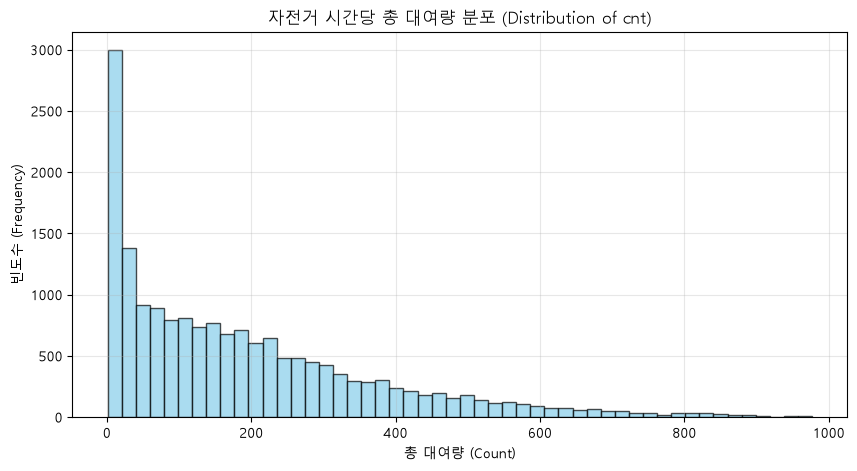

In [5]:
# TODO 1-4. cnt의 분포를 히스토그램으로 시각화합니다.
# 힌트: plt.hist(), plt.xlabel(), plt.ylabel(), plt.show()

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['cnt'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)  # 영문 컬럼명 'cnt' 사용
plt.xlabel('총 대여량 (Count)')                                           # X축 라벨 (한글)
plt.ylabel('빈도수 (Frequency)')                                            # Y축 라벨 (한글)
plt.title('자전거 시간당 총 대여량 분포 (Distribution of cnt)')                # 그래프 제목 (한글)
plt.grid(alpha=0.3)
plt.show()

In [13]:
# TODO 1-5. 시간대(hr)별 평균 대여량을 계산합니다.
# 힌트: groupby("hr")["cnt"].mean()
# 1. 시간대별 평균 대여량을 구하고 데이터프레임으로 변환
hourly_mean = df.groupby("hr")["cnt"].mean().reset_index()

# 2. 컬럼 이름을 원하는 형태로 변경 
hourly_mean.columns = ["hr", "cnt"]

# 3. 결과 출력
print(hourly_mean)

    hr         cnt
0    0   53.898072
1    1   33.375691
2    2   22.869930
3    3   11.727403
4    4    6.352941
5    5   19.889819
6    6   76.044138
7    7  212.064649
8    8  359.011004
9    9  219.309491
10  10  173.668501
11  11  208.143054
12  12  253.315934
13  13  253.661180
14  14  240.949246
15  15  251.233196
16  16  311.983562
17  17  461.452055
18  18  425.510989
19  19  311.523352
20  20  226.030220
21  21  172.314560
22  22  131.335165
23  23   87.831044


Index(['hr', 'cnt'], dtype='str')
   hr        cnt
0   0  53.898072
1   1  33.375691
2   2  22.869930
3   3  11.727403
4   4   6.352941


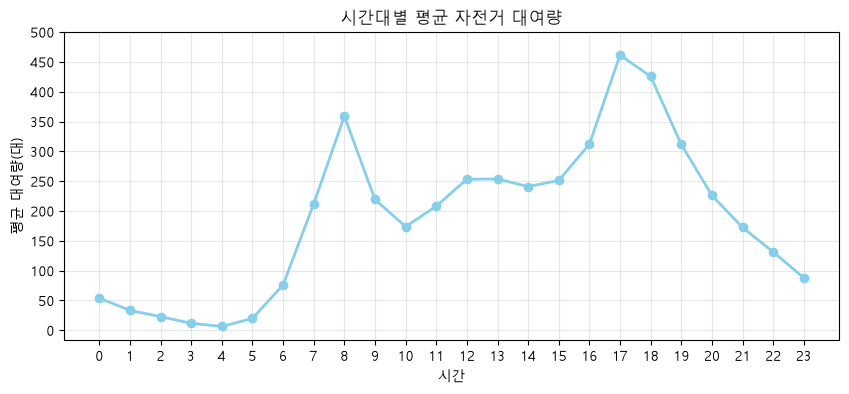

In [15]:
print(hourly_mean.columns)
print(hourly_mean.head())


# [공통] 그래프 기본 설정
plt.figure(figsize=(10, 4))

# TODO 1-6. 시간대별 평균 대여량 선 그래프를 그립니다.
# 💡 데이터프레임의 '시간'과 '평균 대여량(대)' 컬럼을 직접 지정합니다.
plt.plot(hourly_mean["hr"], hourly_mean["cnt"], marker="o", color="skyblue", linewidth=2)


plt.xticks(range(0, 24))

# 💡 세로축 눈금 설정: 0부터 데이터 최대값까지 50 간격으로 촘촘하게 표시
max_val = int(hourly_mean["cnt"].max())
plt.yticks(np.arange(0, max_val + 50, 50))

plt.xlabel("시간")
plt.ylabel("평균 대여량(대)")
plt.title("시간대별 평균 자전거 대여량")
plt.grid(alpha=0.3) # 그리드 선 투명도
plt.show()

**[CP-01] 완료 기준:** 데이터 크기·결측값·중복 여부를 확인하고, `cnt`(총대여량) 분포와 시간대별 평균 대여량 그래프를 완성합니다.

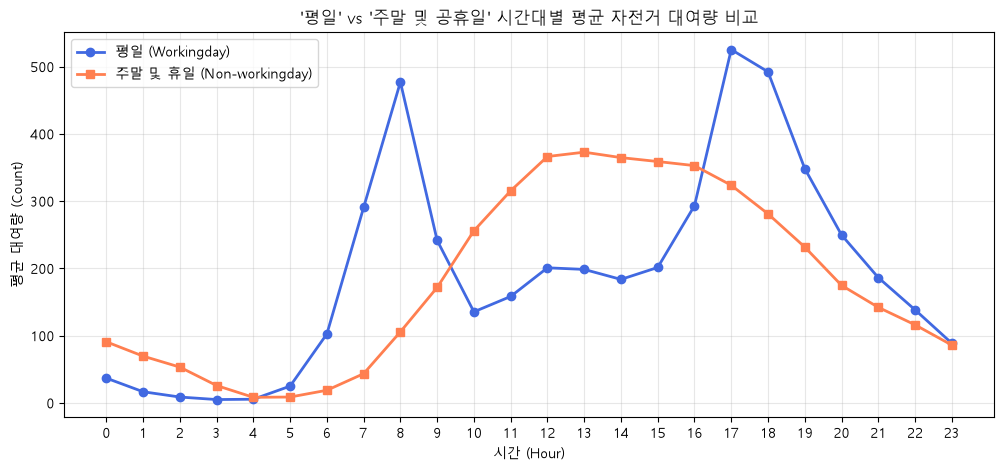

In [16]:
# [선택 심화] 평일과 주말(공휴일 포함)의 시간대별 평균 대여량 비교

# 1. 영문 컬럼 기준으로 평일(1)과 주말/공휴일(0) 데이터 그룹화 및 평균 계산
weekday_mean = df[df['workingday'] == 1].groupby('hr')['cnt'].mean()
weekend_mean = df[df['workingday'] == 0].groupby('hr')['cnt'].mean()

# 2. 비교 그래프 그리기
plt.figure(figsize=(12, 5))

# 평일 그래프 (workingday == 1)
plt.plot(weekday_mean.index, weekday_mean.values, marker='o', label='평일 (Workingday)', color='royalblue', linewidth=2)

# 주말 및 공휴일 그래프 (workingday == 0)
plt.plot(weekend_mean.index, weekend_mean.values, marker='s', label='주말 및 휴일 (Non-workingday)', color='coral', linewidth=2)

# 3. 그래프 꾸미기 (한글 라벨 적용)
plt.xticks(range(0, 24))
plt.xlabel("시간 (Hour)")
plt.ylabel("평균 대여량 (Count)")
plt.title("'평일' vs '주말 및 공휴일' 시간대별 평균 자전거 대여량 비교")
plt.legend()  # 범례 표시
plt.grid(alpha=0.3) # 격자선 투명도 설정

plt.show()

---
## ② 입력 특성 선택 및 상관관계 분석 — CP-02
**목표:** 날짜별 데이터 분할, 누수 확인, Train 상관관계 분석을 마치고 입력 특성을 결정합니다.

### ②-1. 시간 순서 분할 — 일부 공통 코드 + TODO

In [17]:
# [공통] 날짜 변환 및 시간 순서 정렬

# 1. 'dteday'(날짜) 컬럼의 문자열 데이터를 파이썬이 날짜로 인식할 수 있는 datetime 객체로 변환합니다.
df["dteday"] = pd.to_datetime(df["dteday"])

# 2. 날짜(1순위)와 시간(2순위)을 기준으로 전체 데이터를 시간 흐름 순서대로 정렬하고, 인덱스를 0부터 다시 깔끔하게 재정렬합니다.
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

# 17379 총데이터(시간기준) 건수
dfCount = len(df)
print(dfCount) #17379건

# Train(70%), Validation(15%), Test(15%) 데이터를 나눈다
#  - 비율때문에 같은날 시간이 쪼개지지 않아야 한다(날짜단위로 분할되어야 한다)
# 1)날짜단위로 묶는다
dates = np.sort(df["dteday"].unique())
n_dates = len(dates)
print(n_dates) #731일

# 2)Train(70%), Validation(15%), Test(15%) 날짜수 계산
n_train = int(n_dates * 0.70)                   # Train      약 511일 (70%)
n_valid = int(n_dates * 0.15)                   # Validation 약 109일 (15%)
# n_test =  int(n_dates - n_train - n_valid)      # Test       약 111일 (15%)                                          
# print(n_train, n_valid, n_test)

# 3)전체 날짜 캘린더를 구간별로 슬라이싱 (Train / Valid / Test 명단 확정)
train_dates = dates[:n_train]                         # 앞쪽 70% 날짜
valid_dates = dates[n_train:n_train + n_valid]        # 중간 15% 날짜
test_dates = dates[n_train + n_valid:]                # 나머지 뒷쪽 15% 날짜

# 4)원본 데이터에서 해당 날짜에 속하는 시간별 행들을 통째로 추출 (.copy()로 안전하게 복사)
train_df = df[df["dteday"].isin(train_dates)].copy()
valid_df = df[df["dteday"].isin(valid_dates)].copy()
test_df = df[df["dteday"].isin(test_dates)].copy()

 # [공통] 분할 범위 점검
for name, part in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df),
]:
    # 비율 계산 (%)
    ratio = (len(part) / len(df)) * 100
    
    # 이름, shape, 비율, 그리고 날짜 범위 출력
    print(f"{name} 행: {part.shape} ({ratio:.1f}%)")
    print(part["dteday"].min(), "~", part["dteday"].max())
    print()

17379
731
Train 행: (12139, 17) (69.8%)
2011-01-01 00:00:00 ~ 2012-05-25 00:00:00

Validation 행: (2616, 17) (15.1%)
2012-05-26 00:00:00 ~ 2012-09-11 00:00:00

Test 행: (2624, 17) (15.1%)
2012-09-12 00:00:00 ~ 2012-12-31 00:00:00



### ②-2. 데이터 누수 확인 — TODO

In [18]:
# TODO 2-2. casual + registered == cnt가 모든 행에서 성립하는지 확인합니다.
# 힌트: 비교식과 .all()
calc_sum = df['casual'] + df['registered']
same = (calc_sum == df['cnt']).all()
print(f"전체 행 일치 여부: {same}\n")

# 조건이 거짓(False)인 행찾기
verify_df = pd.DataFrame({
    'casual (비회원)': df['casual'],
    'registered (회원)': df['registered'],
    '계산값 (합산)': calc_sum,
    '실제 cnt (총대여량)': df['cnt'],
    '일치 여부': calc_sum == df['cnt']
})

print(" [데이터 검증 샘플 미리보기 (상위 3개)]")
display(verify_df.head(3))


전체 행 일치 여부: True

 [데이터 검증 샘플 미리보기 (상위 3개)]


,casual (비회원),registered (회원),계산값 (합산),실제 cnt (총대여량),일치 여부
0,3,13,16,16,True
1,8,32,40,40,True
2,5,27,32,32,True


In [19]:

# TODO (추가 확인). casual, registered, cnt의 상관관계를 비교해 봅니다.
corr_matrix = df[['casual', 'registered', 'cnt']].corr()
print("--- 컬럼간 상관관계 분석 ---")
display(corr_matrix)

#총대여량(cnt) = 회원대여량(registered) + 비회원대여량(casual)

--- 컬럼간 상관관계 분석 ---


,casual,registered,cnt
casual,1.000000,0.506618,0.694564
registered,0.506618,1.000000,0.972151
cnt,0.694564,0.972151,1.000000


### ②-3. 상관관계 분석 — TODO

In [20]:
# [공통] 분석에 사용할 컬럼
corr_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]
#             온도     체감온도  습도    풍속         총대여량

# TODO 2-3. Train 데이터로만 상관계수를 계산합니다.
# 힌트: train_df[corr_cols].corr()
corr = train_df[corr_cols].corr()
display(corr.round(3))

# 온도(temp) 와 총대여량
#  -양(+)의 상관관계 (약 0.4 대)
#  -날씨가 따뜻해질수록 대여량 증가
#
# 체감온도(atemp) 와 총대여량
#  -양(+)의 상관관계 (약 0.4 대)
#  -실제 온도와 거의 비슷하게 양의 상관관계
#  -사람이 실제로 느끼는 기온이 높을수록 대여량이 증가
#
# 습도(hum) 와 총대여량
#  -음(-)의 상관관계 (마이너스 값)
#  -습도가 높을수록 대여량 감소
#
# 풍속(windspeed) 와 총대여량
#  -음(-)의 상관관계 (낮은 마이너스 값)
#  -바람이 셀수록 대여량 감소
#  -온도나 습도보다는 영향력이 작음


,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,-0.016,-0.015,0.398
atemp,0.992,1.000,-0.000,-0.058,0.398
hum,-0.016,-0.000,1.000,-0.297,-0.301
windspeed,-0.015,-0.058,-0.297,1.000,0.094
cnt,0.398,0.398,-0.301,0.094,1.000


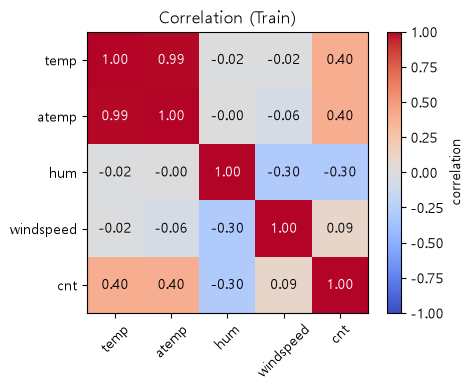

In [21]:
# [공통] 상관관계 시각화 기본 구조
plt.figure(figsize=(5, 4))

# TODO 2-4. 상관관계 행렬을 히트맵으로 시각화합니다.
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")

# (선택 추천) 히트맵 각 칸에 상관계수 수치를 텍스트로 적어주기
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", 
                 ha="center", va="center", 
                 color="black" if abs(corr.iloc[i, j]) < 0.5 else "white")

plt.xticks(range(len(corr_cols)), corr_cols, rotation=45)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation (Train)")
plt.tight_layout()
plt.show()

### ②-4. 입력 특성 선택 — TODO (핵심 의사결정 ①)

In [22]:
# TODO 2-5. 모델에 사용할 입력 컬럼을 선택합니다.
# 다음을 검토하세요: 타깃 cnt, 대여 후 집계값, 행 식별자, 유사한 정보를 가진 컬럼.
# 목록과 제외 이유는 안내 교안에 따라 스스로 결정합니다.
FEATURES = [
    # 1. 꼭 넣어야 하는 핵심 피처 (시간/계절/날씨/날짜 정보)
    "season",     # 계절 (1:봄, 2:여름, 3:가을, 4:겨울)
    "yr",         # 연도 (0:2011, 1:2012)
    "mnth",       # 월 (1~12)
    "hr",         # 시간 (0~23)
    "holiday",    # 휴일 여부 (0/1)
    "weekday",    # 요일 (0~6)
    "workingday", # 근무일 여부 (0/1)
    "weathersit", # 날씨 (1~4)
    "temp",       # 온도
    "atemp",      # 체감온도
    "hum",        # 습도
    "windspeed"   # 풍속
]
# 2. 넣으면 안 되는 것 (치명적 누수): cnt(총 대여량), casual(비회원 대여량), registered(회원 대여량)->정답 및 정답의 구성 요소)
# 3. 상관없는거: instant(행 번호), dteday(날짜 문자열->년+월+요일)
TARGET = "cnt"

print("사용할 특성:", FEATURES)

# 12개의 특성을 사용

사용할 특성: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [23]:
# [공통] 입력 X와 정답 y 분리
X_train = train_df[FEATURES].copy()
X_valid = valid_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET]
y_valid = valid_df[TARGET]
y_test = test_df[TARGET]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)


# 1. 학습 데이터(X_train)의 상위 5개 행(특성들) 확인
print("--- [학습 데이터 X_train 상위 3개] ---")
display(X_train.head(3))

# 2. 정답 데이터(y_train)의 상위 5개 값(총 대여량 cnt) 확인
print("\n--- [정답 데이터 y_train 상위 3개] ---")
display(y_train.head(3))

Train: (12139, 12) (12139,)
Validation: (2616, 12) (2616,)
Test: (2624, 12) (2624,)
--- [학습 데이터 X_train 상위 3개] ---


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0



--- [정답 데이터 y_train 상위 3개] ---


0    16
1    40
2    32
Name: cnt, dtype: int64

**[CP-02] 완료 기준 :** 분할한 데이터의 기간·크기를 확인하고, 누수 검증 결과·Train 상관관계 표·선택한 `FEATURES`를 설명할 수 있습니다.

---
## ③ 특성공학 및 데이터 전처리 — CP-03
**목표:** 출퇴근 시간 특성을 생성하고, 인코딩·표준화·전처리 결합을 구현합니다.

### ③-1. 출퇴근 특성 생성 — TODO

In [25]:
# [공통] 실습에서 사용할 출퇴근 시간 가정
COMMUTE_HOURS = [7, 8, 9, 17, 18, 19]


def add_commute_feature(X):
    """기존 hr와 workingday로 is_commute_hour 특성을 추가합니다."""
    X = X.copy()

    # TODO 3-1. workingday == 1이면서 hr이 COMMUTE_HOURS에 있으면 1, 아니면 0
    X['is_commute_hour'] = ((X['workingday'] == 1) & (X['hr'].isin(COMMUTE_HOURS))).astype(int)

    return X


# [공통] 모든 집합에 같은 특성공학 함수 적용
X_train = add_commute_feature(X_train)
X_valid = add_commute_feature(X_valid)
X_test = add_commute_feature(X_test)

In [ ]:
# [공통] 간단 검증 — 기대 결과는 [1, 0, 0, 1]
check = pd.DataFrame({"hr": [8, 8, 14, 18], "workingday": [1, 0, 1, 1]})
print(add_commute_feature(check))

   hr  workingday  is_commute_hour
0   8           1                1
1   8           0                0
2  14           1                0
3  18           1                1


## 이 정도는 모델이 규칙으로 알아내야 하지 않나요?  친절할수록 좋은걸까요?

### ③-2. 특성 유형 구분 및 ColumnTransformer — TODO

In [26]:
# TODO 3-2. 선택한 입력 특성을 세 유형으로 구분합니다.
# 범주형(One-Hot 인코딩), 수치형(StandardScaler), 이진형(그대로 사용)
# ②교시 FEATURES와 새로 만든 is_commute_hour가 모두 포함되어야 합니다.

# 23시 다음에 0시를 알려줌
for df in [X_train, X_valid, X_test]:
    df['hr_sin'] = np.sin(2 * np.pi * df['hr'] / 24.0)
    df['hr_cos'] = np.cos(2 * np.pi * df['hr'] / 24.0)


# 1. 범주형 특성 (One-Hot 인코딩 대상): 크기/대소 비교 의미가 없고 '종류'를 나타내는 컬럼
categorical_features = [
    "season",     # 계절 (1:봄, 2:여름, 3:가을, 4:겨울)
    "mnth",       # 월 (1~12월)
    "hr",         # 시간 (0~23시)
    "weekday",    # 요일 (0~6)
    "weathersit"  # 날씨 상태 (1~4)
]

# 2. 수치형 특성 (StandardScaler 정규화 대상): 연속적인 실수 값을 가지며 범위 조정이 필요한 컬럼
numeric_features = [
    "temp",       # 온도
    "atemp",      # 체감온도
    "hum",        # 습도
    "windspeed",   # 풍속
    "hr_sin",     # 시간 주기성 (sin)
    "hr_cos"      # 시간 주기성 (cos)
]

# 3. 이진형 특성 (변환 없이 그대로 사용): 이미 0과 1의 값으로 플래그(깃발) 역할을 하는 컬럼
binary_features = [
    "yr",               # 연도 (0:2011, 1:2012)
    "holiday",          # 휴일 여부 (0/1)
    "workingday",       # 근무일 여부 (0/1)
    "is_commute_hour"   # 방금 만든 출퇴근 시간 여부 (0/1)
]

# [공통] 중복/누락 없는지 확인
all_features = categorical_features + numeric_features + binary_features
assert len(all_features) == len(set(all_features)), "특성 목록이 중복됩니다."
assert set(all_features) == set(X_train.columns), "분류되지 않은 컬럼이 있습니다."

print("범주형:", categorical_features)
print("수치형:", numeric_features)
print("이진형:", binary_features)

범주형: ['season', 'mnth', 'hr', 'weekday', 'weathersit']
수치형: ['temp', 'atemp', 'hum', 'windspeed', 'hr_sin', 'hr_cos']
이진형: ['yr', 'holiday', 'workingday', 'is_commute_hour']


In [27]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


def make_preprocessor():
    # TODO 3-3. 다음 세 변환을 ColumnTransformer로 결합합니다.
    # 범주형: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    # 수치형: StandardScaler()
    # 이진형: "passthrough"
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
            ('num', StandardScaler(), numeric_features),
            ('bin', 'passthrough', binary_features)
        ]
    )
    
    return preprocessor


# [공통] 전처리 객체 생성
preprocessor = make_preprocessor()

### ③-3. 전처리 결과 확인 — 공통 코드

In [28]:
# Train에서만 전처리 기준을 학습합니다.
Xt_train = preprocessor.fit_transform(X_train)
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 15) → 변환 후: (12139, 61)
변환 전 Valid: (2616, 15) → 변환 후: (2616, 61)


In [29]:
# 변환된 데이터 까보기  13-->19개로 늘어남

# 1. 원핫 인코딩된 범주형 컬럼 이름 + 수치형/이진형 컬럼 이름 결합 (총 59개)
cat_encoder = preprocessor.named_transformers_['cat']
cat_onehot_features = list(cat_encoder.get_feature_names_out(categorical_features))
all_transformed_columns = cat_onehot_features + numeric_features + binary_features

# 2. 학습 데이터(Xt_train) DataFrame 변환 및 출력
print("--- [학습 데이터: Xt_train 상위 3개] ---")
df_Xt_train = pd.DataFrame(Xt_train, columns=all_transformed_columns)
display(df_Xt_train.head(3))

# 3. 검증 데이터(Xt_valid) DataFrame 변환 및 출력
print("\n--- [검증 데이터: Xt_valid 상위 3개] ---")
df_Xt_valid = pd.DataFrame(Xt_valid, columns=all_transformed_columns)
display(df_Xt_valid.head(3))

--- [학습 데이터: Xt_train 상위 3개] ---


,season_1,season_2,season_3,season_4,mnth_1,mnth_2,mnth_3,mnth_4,mnth_5,mnth_6,...,temp,atemp,hum,windspeed,hr_sin,hr_cos,yr,holiday,workingday,is_commute_hour
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-1.208047,-0.959972,0.913554,-1.567303,0.007900,1.420000,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-1.314183,-1.049681,0.863642,-1.567303,0.374151,1.371839,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-1.314183,-1.049681,0.863642,-1.567303,0.715443,1.230638,0.0,0.0,0.0,0.0



--- [검증 데이터: Xt_valid 상위 3개] ---


,season_1,season_2,season_3,season_4,mnth_1,mnth_2,mnth_3,mnth_4,mnth_5,mnth_6,...,temp,atemp,hum,windspeed,hr_sin,hr_cos,yr,holiday,workingday,is_commute_hour
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.914656,0.739198,1.013380,-0.255427,0.007900,1.420000,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.914656,0.739198,1.013380,-0.494313,0.374151,1.371839,1.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.914656,0.739198,1.312856,-0.494313,0.715443,1.230638,1.0,0.0,0.0,0.0


**[CP-03] 완료 기준:** `is_commute_hour`를 생성하고 `make_preprocessor()`가 정상 실행되며, Train/Validation 변환 결과를 출력합니다.


In [30]:
# **선택 심화:** 시간대의 주기성을 반영하는 특성을 추가해 봅니다.
# 23시 다음이 0 시임을 알려준다
# 위쪽에 추가했음
'''
for df in [X_train, X_valid]:
    # 24시간을 둥근 원(주기) 형태로 변환하여 sin, cos 특성 생성
    df['hr_sin'] = np.sin(2 * np.pi * df['hr'] / 24.0)
    df['hr_cos'] = np.cos(2 * np.pi * df['hr'] / 24.0)
'''

"\nfor df in [X_train, X_valid]:\n    # 24시간을 둥근 원(주기) 형태로 변환하여 sin, cos 특성 생성\n    df['hr_sin'] = np.sin(2 * np.pi * df['hr'] / 24.0)\n    df['hr_cos'] = np.cos(2 * np.pi * df['hr'] / 24.0)\n"

---
## ④ 기준 모델 및 선형회귀 — CP-04
**목표:** DummyRegressor·LinearRegression을 학습하고 MAE·RMSE·R² 공통 평가 함수를 구현합니다.

### ④-1. 모델 구성과 학습 — TODO

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# TODO 4-1. 전처리 + DummyRegressor(strategy="mean") Pipeline 구현
# 기준선(baseline) 모델: 입력 특성은 보지 않고 학습 데이터 cnt의 평균만 예측
# 이후 모델이 이보다 좋아졌는지 비교하는 최저 기준
dummy_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("model", DummyRegressor(strategy="mean")),
])


# TODO 4-2. 전처리 + LinearRegression() Pipeline 구현
# 실제 예측 모델: 특성과 cnt 사이의 선형 관계를 학습
# 이후 더 복잡한 모델과 비교할 출발점
linear_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("model", LinearRegression()),
])

# [공통] 모델 학습
dummy_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
print("학습 완료")

학습 완료


### ④-2. 평가 함수 — TODO / 결과 정리 함수 — 공통

In [32]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)


def evaluate_regression(model, X, y):
    """MAE, RMSE, R2 딕셔너리를 반환합니다."""
    # TODO 4-3. model.predict(X)로 예측하고 세 지표를 계산합니다.
    pred =  model.predict(X)
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": root_mean_squared_error(y, pred),
        "R2": r2_score(y, pred),
    }


def summarize(name, model):
    """Train·Validation 평가를 한 행으로 정리합니다 (공통)."""
    tr = evaluate_regression(model, X_train, y_train)
    va = evaluate_regression(model, X_valid, y_valid)
    return {
        "Model": name,
        "Train MAE": tr["MAE"],
        "Train RMSE": tr["RMSE"],
        "Train R2": tr["R2"],
        "Valid MAE": va["MAE"],
        "Valid RMSE": va["RMSE"],
        "Valid R2": va["R2"],
    }

In [33]:
# [공통] 이후 교시에서 결과를 누적할 리스트
results = []
results.append(summarize("DummyRegressor", dummy_model))
results.append(summarize("LinearRegression", linear_model))

# TODO 4-4. 두 모델의 성능을 DataFrame으로 비교합니다.
# 힌트: pd.DataFrame(results).round(3)
results_df = pd.DataFrame(results).round(3)
display(results_df)

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2
0,DummyRegressor,119.572,152.40,0.000,194.109,253.892,-0.296
1,LinearRegression,55.334,73.41,0.768,99.854,124.008,0.691


**[CP-04] 완료 기준:** 두 모델을 학습하고 공통 평가 함수로 Train·Validation 성능을 표로 비교합니다.

## Linear 결과 해석

1. 모든 지표가 더미보다 좋아서, 전처리와 특성 선택에 큰 문제는 없고 기본적인 학습은 이루어졌다
2. 일단 학습에서는 R2가 0.768로 더미에 비해 비교적 높고 검증에서 R2 0.691 소폭만 떨어져 학습효과가 유지되었다
3. 학습에서 R2의 점수가 고득점(1에 가까운) 점수가 아니라서 과대 적합을 의심할 정도는 아니다
4. 학습 R2가 0.768로 아주 높지는 않아 과소적합일 수 있으므로, 더 복잡한 모델(트리등)로 확인해 볼 필요가 있다
5. 학습 MAE에서 검증 MAE로 커진 차이는 계절적 영향이 있을 것 같다(선생님 의견). 
   과대적합을 의심할 정도는 아니며, 계절별 오차 등 다른 방법으로 추가 확인해 본다.

---
## ⑤ Decision Tree 모델 개선 — CP-05
**목표:** `max_depth`를 바꿔 학습·검증 MAE를 비교하고 그래프로 표현합니다.

### ⑤-1. 깊이별 모델 학습 — TODO

In [34]:
from sklearn.tree import DecisionTreeRegressor

# [공통] 실험 설정 및 저장 구조
depths = [3, 6, 12]
tree_models = {}
tree_results = []

# TODO 5-1~5-3. 각 깊이별 Pipeline 생성·학습·평가 결과 수집
for d in depths:
    # TODO 5-1. 전처리 + DecisionTreeRegressor(max_depth=d, random_state=42)
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", DecisionTreeRegressor(max_depth=d, random_state=42)),
    ])

    # TODO 5-2. 모델 학습
    model.fit(X_train, y_train)

    # [공통] 학습한 모델 보관
    tree_models[d] = model

    # TODO 5-3. summarize()로 성능 결과 수집
    row = summarize(f"DecisionTree(depth={d})", model)
    tree_results.append(row)
    results.append(row)

# [공통] 결과 정리
tree_df = pd.DataFrame(tree_results)
tree_df["max_depth"] = depths
display(tree_df.round(3))

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,max_depth
0,DecisionTree(depth=3),69.480,96.932,0.595,119.305,166.012,0.446,3
1,DecisionTree(depth=6),42.103,62.783,0.830,64.793,91.780,0.831,6
2,DecisionTree(depth=12),15.270,26.541,0.970,59.022,93.285,0.825,12


### ⑤-2. 모델 복잡도와 오차 시각화 — TODO

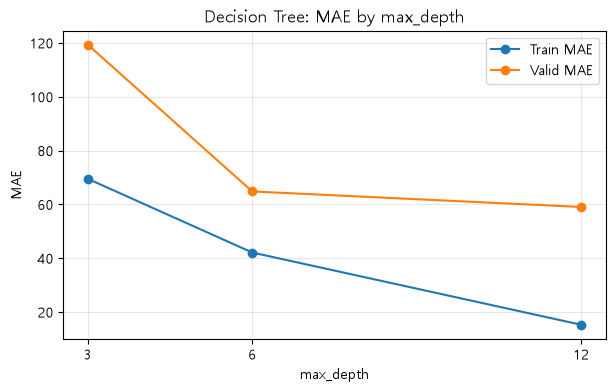

In [35]:
# [공통] 시각화 기본 설정
plt.figure(figsize=(7, 4))

# TODO 5-4. 깊이별 Train MAE와 Validation MAE를 각각 선 그래프로 표시합니다.
# 힌트: plt.plot(tree_df["max_depth"], tree_df["Train MAE"], ...)
plt.plot(tree_df["max_depth"], tree_df["Train MAE"], marker="o", label="Train MAE")
plt.plot(tree_df["max_depth"], tree_df["Valid MAE"], marker="o", label="Valid MAE")

plt.xticks(depths)
plt.xlabel("max_depth")
plt.ylabel("MAE")
plt.title("Decision Tree: MAE by max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**[CP-05]완료 기준:** 깊이 3·6·12의 성능표와 Train·Validation MAE 그래프를 완성합니다.

**선택 심화:** `min_samples_leaf` 설정을 추가로 실험합니다.

## Decision Tree 결과 해석

Linear는 Dummy보다는 좋았지만 Train R2가 0.768에 그치고 Valid MAE가 99.9로 아쉬워, 과소적합을 의심하고 더 복잡한 모델인 결정 트리로 새로 실험했다. 먼저 과대적합이 의심되는 깊이 12를 점검하고, 반대쪽 끝인 깊이 3과 비교해 균형 잡힌 깊이를 고른다.

1. 깊이 12는 과대적합이 의심된다.

   - 학습 R2가 0.970으로 만점 근처인데 검증 R2는 0.825로 0.145 떨어졌다.
   - 학습 MAE 15.3에서 검증 MAE 59.0으로 약 3.9배 나빠졌다. (Linear는 약 1.8배)

2. 깊이 12는 검증 MAE만 약간 낮을 뿐, 깊이 6보다 이득이 없어 제외한다.

   - 검증 MAE는 깊이 12(59.022)가 깊이 6(64.793)보다 약간 낮다.
   - 그러나 검증 RMSE(93.285 대 91.780)와 R2(0.825 대 0.831)는 오히려 나빠졌다.
   - 깊이를 2배로 늘린 만큼의 이득이 없고 과대적합 위험만 커졌다.

3. 깊이 6을 선택한다.

   - 학습 R2 0.830, 검증 R2 0.831로 격차가 거의 없어 과대적합 신호가 없다.
   - 학습 R2가 Linear(0.768)보다 높아 과소적합도 많이 해소되었다.
   - 너무 복잡하지도 단순하지도 않은 균형 지점이다.

4. 반대로 깊이 3은 과소적합이라 제외한다.

   - 학습 R2 0.595, 검증 R2 0.446으로 둘 다 낮다.
   - Linear(검증 R2 0.691)보다도 나쁘다.
   - 질문 횟수가 부족해 패턴을 다 담지 못했다.

5. 깊이를 3에서 6으로 늘리자 학습과 검증 R2가 함께 크게 올랐다(검증 0.446에서 0.831).

   - Linear에서 세운 과소적합 가설이 확인되었다.
   - 시간대와 날씨의 조합 같은 비선형 패턴을 트리가 잡은 것으로 보인다.

6. Linear 대비 깊이 6은 검증 기준으로 모든 지표가 좋아졌다.

   - MAE 99.9에서 64.8 (약 35% 감소)
   - RMSE 124.0에서 91.8 (약 26% 감소)
   - R2 0.691에서 0.831
   - 모델 후보로 Linear 대신 트리(깊이 6)를 선택한다.

---
## ⑥ Random Forest 및 모델 통합 비교 — CP-06
**목표:** Random Forest 두 설정을 실험하고 네 종류 모델의 성능을 하나의 표로 비교합니다.

### ⑥-1. Random Forest 실험 — TODO

In [36]:
from sklearn.ensemble import RandomForestRegressor

# [공통] 비교할 두 설정
rf_configs = {
    "A": {"n_estimators": 50, "max_depth": 10},
    "B": {"n_estimators": 100, "max_depth": 15},
}
rf_models = {}

# TODO 6-1~6-2. 두 설정의 Random Forest Pipeline 학습 및 성능 수집
for key, params in rf_configs.items():
    # TODO: Pipeline 구성 (RandomForestRegressor(**params, random_state=42, n_jobs=-1))
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestRegressor(**params, random_state=42, n_jobs=-1)),
    ])

    # TODO: 모델 학습
    model.fit(X_train, y_train)

    # [공통] 학습한 모델 보관
    rf_models[key] = model

    # TODO: summarize()로 결과를 results에 추가합니다.
    row = summarize(f"RandomForest({key}: n={params['n_estimators']}, depth={params['max_depth']})", model)
    results.append(row)

### ⑥-2. 전체 성능표 비교 — TODO

In [37]:
# [공통] 지금까지 누적한 모델 결과
results_df = pd.DataFrame(results)

# TODO 6-3. Validation MAE가 낮은 순서로 정렬하고 인덱스를 정리합니다.
results_df = results_df.sort_values("Valid MAE").reset_index(drop=True)

# TODO 6-4. Validation MAE - Train MAE를 계산합니다.
results_df["Gap (Valid-Train MAE)"] = results_df["Valid MAE"] - results_df["Train MAE"]

display(results_df.round(3))

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,Gap (Valid-Train MAE)
0,"RandomForest(B: n=100, depth=15)",10.851,17.252,0.987,46.091,72.282,0.895,35.240
1,"RandomForest(A: n=50, depth=10)",20.101,31.084,0.958,47.494,72.799,0.893,27.393
2,DecisionTree(depth=12),15.270,26.541,0.970,59.022,93.285,0.825,43.753
3,DecisionTree(depth=6),42.103,62.783,0.830,64.793,91.780,0.831,22.690
4,LinearRegression,55.334,73.410,0.768,99.854,124.008,0.691,44.520
5,DecisionTree(depth=3),69.480,96.932,0.595,119.305,166.012,0.446,49.825
6,DummyRegressor,119.572,152.400,0.000,194.109,253.892,-0.296,74.538


**[CP-06]완료 기준:** Dummy·Linear·Decision Tree·Random Forest 결과를 같은 Validation MAE 기준으로 비교합니다.

이전의 분석으로 

DummyRegressor, LinearRegression, DecisionTree(depth=12), DecisionTree(depth=3)	 제외

DecisionTree(depth=6)는 Train 및 Valid의 MAE, R2 모두 RandomForest 대비 낮은 성능을 보여 제외

In [ ]:
## RandomForest(B: n=100, depth=15), RandomForest(A: n=50, depth=10) 비교

# 비교할 모델만 선택
selected_models = [
    "RandomForest(A: n=50, depth=10)",
    "RandomForest(B: n=100, depth=15)"
]

# 해당 모델만 추출
compare_df = results_df[
    results_df["Model"].isin(selected_models)
].reset_index(drop=True)

display(compare_df.round(3))

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,Gap (Valid-Train MAE)
0,"RandomForest(B: n=100, depth=15)",10.851,17.252,0.987,46.091,72.282,0.895,35.240
1,"RandomForest(A: n=50, depth=10)",20.101,31.084,0.958,47.494,72.799,0.893,27.393


### 분석
- B는 학습성능이 크게 우수했으나 검증에서는 A와 차이가 미미했다(MAE 1.4, R² 0.002)   
- Train-Valid Gap은 B가 35.2로 A(27.4)보다 커 과적합 가능성이 더 높았다.  
- B가 복잡하게 만들어졌는데 비해 일반화 성능 향상이 거의 없으므로 더 단순한 A가 효율적이다

**선택 심화:** 추가 파라미터 탐색이나 시간 순서 교차검증을 시도합니다.

---
## ⑦ 오류 분석 및 최종 모델 선택 — CP-07
**목표:** 두 후보 모델의 예측 오차를 분석하고, 근거를 기록하여 최종 모델을 결정합니다.

### ⑦-1. 후보 모델과 잔차 — TODO

In [46]:
# TODO 7-1. results_df를 검토하여 오류 분석할 후보 모델 2개를 선택합니다.
# tree_models, rf_models 또는 앞서 학습한 모델 객체를 활용합니다.
candidates = {
    "RF_A": rf_models["A"],
    "RF_B": rf_models["B"]
}

# [공통] 실제값과 시간대 DataFrame
pred_df = pd.DataFrame({
    "hr": X_valid["hr"].values,
    "actual": y_valid.values,
})

# TODO 7-2. 각 모델의 Validation 예측값과 잔차를 계산합니다.
for name, model in candidates.items():
    pred_df[f"pred_{name}"] = model.predict(X_valid)
    pred_df[f"resid_{name}"] = (
        pred_df["actual"] - pred_df[f"pred_{name}"]
    )

display(
    pred_df.head().rename(columns={
        "hr": "hr (시간)",
        "actual": "actual (실제값)",
        "pred_RF_A": "pred_RF_A (A 예측)",
        "resid_RF_A": "resid_RF_A (A 잔차)",
        "pred_RF_B": "pred_RF_B (B 예측)",
        "resid_RF_B": "resid_RF_B (B 잔차)"
    })
)

,hr (시간),actual (실제값),pred_RF_A (A 예측),resid_RF_A (A 잔차),pred_RF_B (B 예측),resid_RF_B (B 잔차)
0,0,116,121.167013,-5.167013,133.506328,-17.506328
1,1,82,87.116281,-5.116281,103.445039,-21.445039
2,2,64,61.925918,2.074082,65.752756,-1.752756
3,3,31,29.515743,1.484257,29.015999,1.984001
4,4,2,9.620568,-7.620568,10.465410,-8.465410


### ⑦-2. 실제값과 예측값 시각화 — TODO

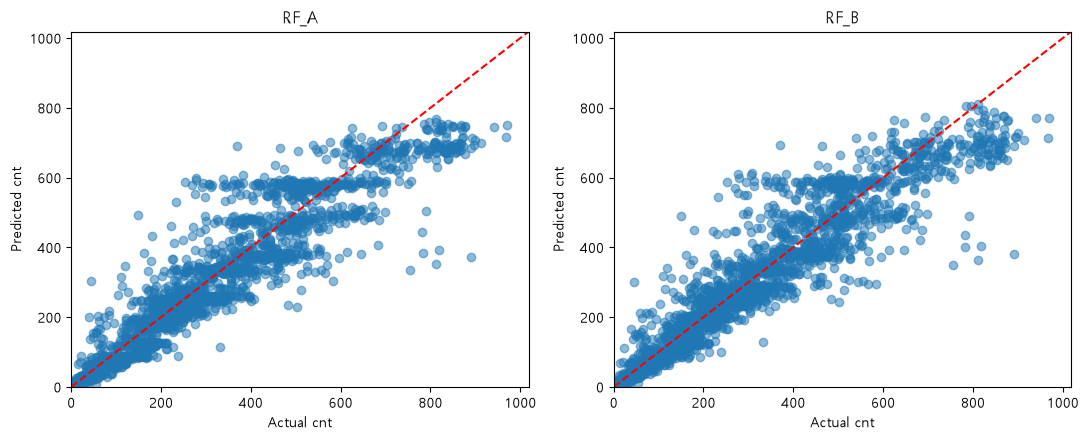

In [51]:
# [공통] 두 후보 모델을 나란히 비교합니다.
assert len(candidates) == 2, "오류 분석 후보를 2개 선택하세요."

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
lim = pred_df["actual"].max() * 1.05

for ax, name in zip(axes, candidates):
    # TODO 7-3. 실제값(x)·예측값(y) 산점도와 y=x 기준선을 작성합니다.
    ax.scatter(
        pred_df["actual"],
        pred_df[f"pred_{name}"],
        alpha=0.5
    )

    # 실제값과 예측값이 일치하는 기준선
    ax.plot([0, lim], [0, lim], "r--", label="Perfect Prediction")

    # [공통] 축 및 제목
    ax.set_xlabel("Actual cnt")
    ax.set_ylabel("Predicted cnt")
    ax.set_title(name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.show()

### 분석
#### 공통
- 비교적 빨간선 근처에 잘 모여 있음, 특히 0~300 구간에 잘 맞음  
- 대여량이 많을 수록 점이 넓게 펴짐, 큰 값일수록 예측하기 어려움  
- 두모델이 공통으로 오차가 있어 모델설정보다 날씨 이벤트 등의 영향일 가능성이 있음  

#### RF_A
- 예측값이 700~750 부근에서 더 올라가지 못함
- 실제값이 800 이상이어도 예측은 700대에 머무름
- 예측값 380, 480, 580 부근에 가로줄이 보임
- 실제값은 다양한데 예측값은 몇 개의 값으로 묶여 나온다는 뜻이므로, 예측이 단순한 편임

#### RF_B
- 예측값이 800 부근까지 올라가고 선에 가까운 점이 늘어남
- 가로줄이 흐려지고 점이 선을 따라 이어져서 예측이 더 세밀함
- 다만 높은 구간에서 점이 더 넓게 퍼져 들쭉날쭉한 면이 있음
- 900 이상의 매우 큰 값은 여전히 700대로 예측함

#### 평가
- RF_B가 고수요 구간과 예측 세밀함에서 조금 더 좋아 보임
- 저수요 구간과은 두 모델의 차이가 거의 없음
- 대략적인 성향의 비교라서 검증쪽 MAE, RMSE, R² 같은 수치와 **시간대별** MAE로 확인하는 것이 필요함


### ⑦-3. 시간대별 MAE — TODO

In [52]:
# [공통] 시간대별 오류 DataFrame
hourly_mae = pd.DataFrame(index=range(24))
hourly_mae.index.name = "hr"

for name in candidates:
    # TODO 7-4. 모델별 절대오차와 시간대별 평균 절대오차를 계산합니다.
    # 모델별 절대오차 계산
    abs_err = np.abs(
        pred_df["actual"] - pred_df[f"pred_{name}"]
    )
    
    # 시간대별 평균 절대오차 계산
    hourly_mae[name] = (
        abs_err.groupby(pred_df["hr"]).mean()
    )

display(hourly_mae.round(1))

,RF_A,RF_B
hr,,
0,25.0,21.7
1,14.2,12.2
2,10.2,8.5
3,4.7,4.1
4,3.5,3.3
5,12.1,10.3
6,30.3,31.6
7,52.6,49.8
8,47.5,53.1


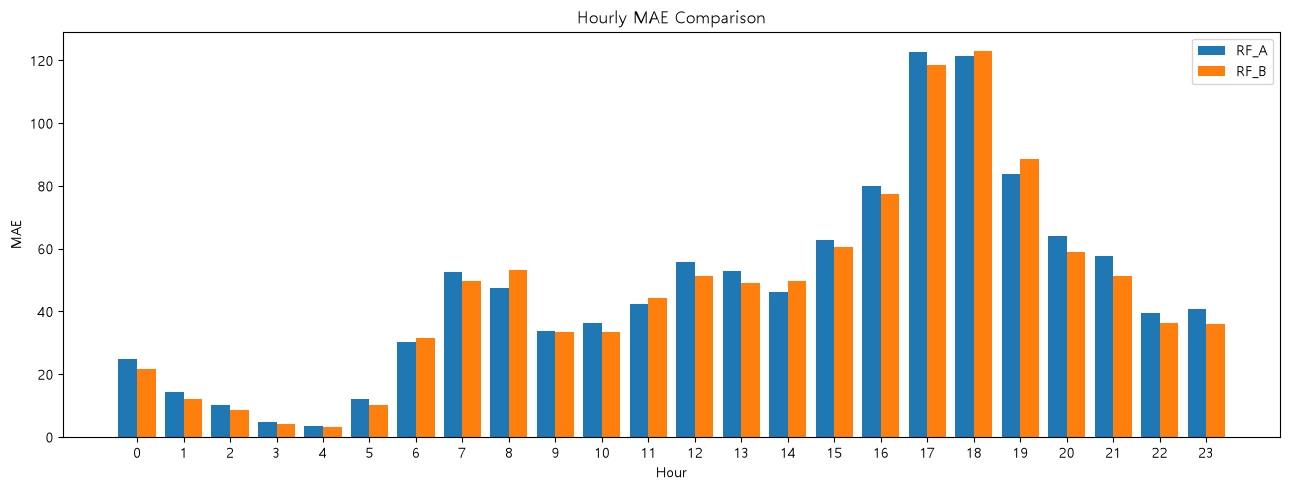

In [53]:
# TODO 7-5. 후보 모델들의 시간대별 MAE를 막대그래프로 표현합니다.
# 힌트: plt.bar(), hourly_mae
plt.figure(figsize=(13, 5))

plt.bar(hourly_mae.index - 0.2, hourly_mae["RF_A"], width=0.4, label="RF_A")
plt.bar(hourly_mae.index + 0.2, hourly_mae["RF_B"], width=0.4, label="RF_B")

plt.xlabel("Hour")
plt.ylabel("MAE")
plt.title("Hourly MAE Comparison")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()

### 분석 
- 오차가 가장 큰 시간대는 17~18시로, MAE가 120 정도로 다른 시간대보다 훨씬 큼
- 퇴근 시간대는 수요가 크고 변동도 커서 맞추기 가장 어려움
- 오전 7~8시(출근)와 15~19시에 오차가 큰 편임
- 새벽(2~5시)은 수요가 적어서 MAE도 매우 작음
- 새벽에는 RF_B가 아주 조금 더 좋지만 차이는 미미함

### 결론
- 산점도에서는 RF_B가 더 좋아 보였지만, 시간대별로 보면 차이가 크지 않음
- 두 모델 모두 퇴근 시간대(17~18시)가 가장 큰 약점임


### ⑦-4. 최종 모델 선택 — 기록

**TODO 7-6:**  
results_df의 Validation MAE, Train·Validation 성능 차이, 예측 오류 분석 결과를 비교하여 최종 모델과 설정을 선택합니다.  
선택한 모델과 그 근거는 adr.md의 의사결정 ②에 기록합니다.  
선택한 모델과 설정은 ⑧교시의 최종 학습에 사용합니다.  


### 1. 최종 모델 선택
**선택 모델:** `RandomForest (A: n=50, depth=10)`

---

### 2. 선택 근거

* **검증 지표 및 실전 오차 분석**
  * 검증 MAE(47.494), RMSE(72.799), R²(0.893) 지표상 `RF_B` 대비 성능 차이가 미세함.
  * Actual vs Predicted 산점도와 시간대별 MAE 패턴 분석에서도 두 모델 간 예측 경향이 전반적으로 유사함.
  * 피크 시간대 오차 감소라는 미세한 실익에 비해 성능 우위 폭이 대단히 제한적임.

* **과적합(Overfitting) 리스크 회피**
  * `RF_B`는 Train R²가 0.987에 달해 학습 데이터를 거의 암기한 수준임.
  * `RF_B`의 Train-Validation MAE Gap(35.240)은 `RF_A`(27.393)보다 훨씬 크며 뚜렷한 과적합 신호를 보임.
  * 튜닝 복잡도를 높인 보상이 미미한 반면, 과적합으로 인한 실전 성능 불안정 리스크가 훨씬 큼.

* **최종 채택 결론**
  * 미세한 검증 오차 우수성에 집착하기보다, 모델의 일반화 안정성을 확보하는 것이 실무적으로 안전함.
  * 따라서 과적합 위험을 경계하고 오차 격차(Gap)가 적은 `RF_A`를 최종 선택함.

**[CP-07] 완료 기준:** 잔차와 시간대별 MAE 분석을 완료하고 최종 모델 선택 이유를 설명합니다.

**선택 심화:** Permutation Importance로 입력 특성의 기여도를 분석합니다 (필수 아님).

In [ ]:
# [선택 심화] 특성 중요도
# TODO (선택): sklearn.inspection.permutation_importance 를 사용해
# Validation 데이터에서 각 입력 특성을 섞었을 때 MAE가 얼마나 변하는지 분석합니다.
# 이 셀을 실행하지 않아도 ⑧교시 진행에 영향이 없습니다.


---
## ⑧ 최종 모델 완성 및 예측 — CP-08
**목표:** 선택한 모델을 재학습하고 Test 평가, 모델 저장·재로딩, 입력 한 건 예측까지 구현합니다.

### ⑧-1. 최종 모델 재학습 — TODO

In [ ]:
import joblib
from pathlib import Path

# [공통] Train과 Validation 데이터 결합
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])

# TODO 8-1. ⑦에서 선택한 모델과 하이퍼파라미터로 새 estimator를 생성합니다.
# 예: 앞서 사용한 회귀 모델 클래스와 선택한 설정을 사용합니다.
final_estimator = ...

# [공통] 최종 Pipeline은 전처리를 포함해야 합니다.
final_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", final_estimator),
])

# TODO 8-2. Train + Validation으로 최종 모델을 재학습합니다.
...

### ⑧-2. Test 평가 — TODO

In [ ]:
# TODO 8-3. Test 데이터에 대해 최종 MAE·RMSE·R2를 평가합니다.
# ④에서 작성한 evaluate_regression()을 재사용합니다.
test_scores = ...
print("최종 Test 성능:", test_scores)

### ⑧-3. 최종 모델 저장과 재로딩 — TODO

In [ ]:
# [공통] 결과 폴더와 저장 경로
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_PATH = RESULTS_DIR / "01_final_model.joblib"

# TODO 8-4. 전처리+모델 Pipeline을 joblib으로 저장합니다 (compress=3).
...

# TODO 8-5. 저장된 Pipeline을 다시 불러옵니다.
loaded_model = ...

# TODO 8-6. 저장 전후 예측 결과가 일치하는지 확인합니다.
# 힌트: np.allclose(), X_test.iloc[:100]
same_pred = ...
print("저장 전후 예측 일치:", same_pred)

In [ ]:
# [공통] 실험 결과표 저장
results_df.round(3).to_csv(
    RESULTS_DIR / "01_model_comparison.csv", index=False
)
hourly_mae.round(2).to_csv(
    RESULTS_DIR / "01_hourly_mae_validation.csv"
)
print("결과 파일:", sorted(p.name for p in RESULTS_DIR.iterdir()))

### ⑧-4. 단일 입력 예측 함수 — TODO

In [ ]:
def predict_demand(
    model, season, yr, mnth, hr, holiday,
    weekday, workingday, weathersit, temp, hum, windspeed
):
    """한 시간의 입력 조건으로 예상 대여량(정수)을 반환합니다.

    temp, hum, windspeed는 hour.csv와 같은 정규화 값(0~1)으로 입력합니다.
    """
    # TODO 8-7. 전달받은 값으로 입력 1행 DataFrame을 만듭니다.
    # 학습에 사용한 FEATURES 컬럼을 정확히 사용해야 합니다.
    row = ...

    # TODO 8-8. ③에서 만든 동일한 특성공학 함수를 적용합니다.
    row = ...

    # TODO 8-9. 예측값 하나를 구해 정수로 반환합니다.
    pred = ...
    return ...


# [공통] 섭씨 온도를 원본 데이터의 정규화 기온으로 변환
def celsius_to_temp(c):
    return (c + 8) / 47


# [공통] 예측 입력 예제
sample = {
    "season": 4,
    "yr": 1,
    "mnth": 10,
    "hr": 18,
    "holiday": 0,
    "weekday": 3,
    "workingday": 1,
    "weathersit": 1,
    "temp": celsius_to_temp(20),
    "hum": 0.50,
    "windspeed": 0.15,
}

# TODO 8-10. 저장한 모델과 sample을 사용해 predict_demand()를 호출합니다.
# 힌트: predict_demand(loaded_model, **sample)
result = ...
print("예상 대여량:", result)

**[CP-08] 완료 기준 :** 최종 재학습·Test 평가·모델 저장·재로딩·예측 함수가 정상 동작하면 프로젝트 코드가 완성됩니다.